## Import Libry

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [2]:
df = pd.read_csv('Laprak_Scraping.csv')

df['harga'] = df['harga_teks'].astype(str).str.replace(r'[^0-9.]', '', regex=True).astype(float)

print("=== INFO DATASET ===")
print(df.info())

=== INFO DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nama_produk         200 non-null    object 
 1   harga_teks          200 non-null    object 
 2   jumlah_review_teks  200 non-null    int64  
 3   kategori            200 non-null    object 
 4   harga               200 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 7.9+ KB
None


In [4]:
print("\n=== DESKRIPSI STATISTIK ===")
display(df.describe())

print("\n=== JUMLAH DATA KOSONG ===")
print(df.isna().sum())


=== DESKRIPSI STATISTIK ===


,jumlah_review_teks,harga
count,200.0,200.000000
mean,0.0,837.002150
std,0.0,384.294155
min,0.0,295.990000
25%,0.0,454.702500
50%,0.0,854.000000
75%,0.0,1150.807500
max,0.0,1799.000000



=== JUMLAH DATA KOSONG ===
nama_produk           0
harga_teks            0
jumlah_review_teks    0
kategori              0
harga                 0
dtype: int64


In [5]:
print("\n=== KELAS UNIK PADA TARGET ===")
print(df['kategori'].unique())

X_raw = df[['jumlah_review_teks', 'harga']]
y_raw = df['kategori']

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)

X = np.array(X_raw, dtype=np.float64)
y = np.array(y_encoded, dtype=np.int64)

print("Bentuk array X:", X.shape)
print("Bentuk array y:", y.shape)


=== KELAS UNIK PADA TARGET ===
['Phone']
Bentuk array X: (200, 2)
Bentuk array y: (200,)


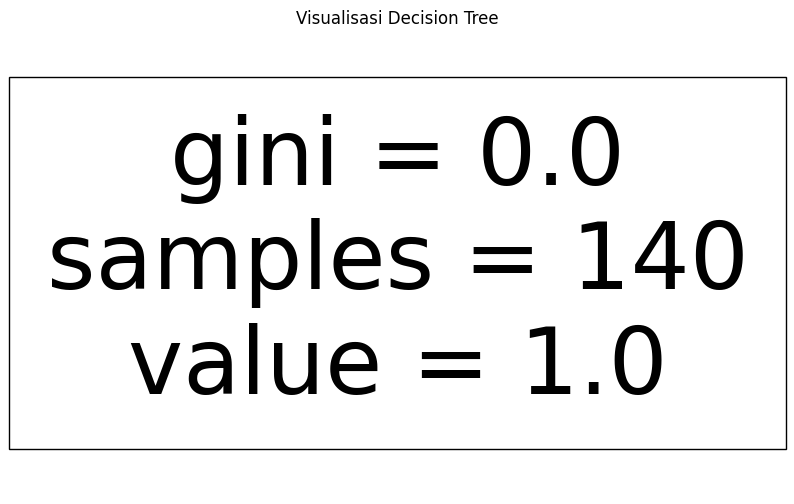


Prediksi untuk data baru [Review=5, Harga=300]: Kelas 'Phone'

Akurasi Model: 1.0000

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

       Phone       1.00      1.00      1.00        60

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

dt_model = DecisionTreeClassifier(random_state=0)
dt_model.fit(X_train, y_train)

plt.figure(figsize=(10, 6))
plot_tree(dt_model, filled=True, feature_names=['jumlah_review_teks', 'harga'], class_names=le.classes_)
plt.title("Visualisasi Decision Tree")
plt.show()

data_baru = np.array([[5.0, 300.0]])
prediksi_angka = dt_model.predict(data_baru)
prediksi_label = le.inverse_transform(prediksi_angka)
print(f"\nPrediksi untuk data baru [Review=5, Harga=300]: Kelas '{prediksi_label[0]}'")

y_pred = dt_model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)
print(f"\nAkurasi Model: {akurasi:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))